ECE 3715 Mini Project 1

Team Members: Jovanni Munoz, 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binom, poisson, geom
from scipy.stats import norm

from mp1lib import (
    bsc,
    packet_errors,
    attempts_until_clean,
    tv_distance
)

print("Setup complete.")

Setup complete.


In [2]:
# Main random number generator (Team number=5)
SEED = 5
rng = np.random.default_rng(SEED)

# Independent generators with one for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

N = 1000000

# Test: BSC and it must return [0, 1, 0, 1] because the p=0
bits = np.array([0, 1, 0, 1])
print(bsc(bits, 0, rng_step1))

# Test: Packet errors
x = packet_errors(10000, 1000, 0, rng_step4)
assert np.all(x == 0)

# Test: Geometric attempts
t = attempts_until_clean(10000, 1, rng_step6)
assert np.all(t == 1)

# Test: Total variation distance
assert tv_distance([0.5, 0.5], [0.5, 0.5]) == 0
assert tv_distance([1, 0], [0, 1]) == 1
print("All function tests passed.")

[0 1 0 1]
All function tests passed.


In [3]:
#Set error probability and create a list
p = 0.1
patterns = []
#Go through all possible bit combinations and change them to binary format
for i in range(16):
    pattern = format(i, "04b")
    patterns.append(pattern)
#Display all bit combinations
print(patterns)
#create a list for the probability of each bit combination
exact_probabilities = []
#Use the formula to calculate probability of each combination
for pattern in patterns:
    k = pattern.count("1")
    probability = (p ** k) * ((1-p) ** (4-k))
    exact_probabilities.append(probability)
#Display the probability of each combination and its sum
print(exact_probabilities)
print("Sum =", sum(exact_probabilities))

['0000', '0001', '0010', '0011', '0100', '0101', '0110', '0111', '1000', '1001', '1010', '1011', '1100', '1101', '1110', '1111']
[0.6561, 0.0729, 0.0729, 0.008100000000000001, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.0729, 0.008100000000000001, 0.008100000000000001, 0.0009000000000000002, 0.008100000000000001, 0.0009000000000000002, 0.0009000000000000002, 0.00010000000000000002]
Sum = 1.0


P(A) = 1−(1−p)^2
P(A) = 1-(1-.1)^2
P(A) = 1-.81 = .19

P(A) = .19


P(B) =  \({4 \choose 2}\)*p^2(1-p)^2
P(B) = (6)*.1^2(1-.1)^2
P(B) = (6)*.1^2(.9)^2

P(B) = .0486

P(C) = .1

In [4]:
#Generate 1000000 packets with 4 bits in each one and error probability of .1
N = 1000000
errors = rng_step1.random((N1, 4)) < 0.1
#Check if A, B, and C happen and how many times
A = np.any(errors[:, :2], axis=1)
B = errors.sum(axis=1) == 2
C = errors[:, 3] 
events = [A, B, C]
#Estimate probability that each one happens
for name, event in zip(["A", "B", "C"], events):
    A_estimate = A.mean()
    B_estimate = B.mean()
    C_estimate = C.mean()

print("Estimate A:", A_estimate)
print("Estimate B:", B_estimate)
print("Estimate C:", C_estimate)

NameError: name 'N1' is not defined

In [80]:
#Compute three pairwise intersections and triple intersections empirically
pairs = [
    ("A and B:", A & B),
    ("A and C:", A & C),
    ("B and C:", B & C),
    ("A and B and C:", A & B & C)
]
AB, AC, BC, ABC = [pair[1] for pair in pairs]

AB_estimate = AB.mean()
AC_estimate = AC.mean()
BC_estimate = BC.mean()
ABC_estimate = ABC.mean()

#print probability of each pair
print("Estimate A and B:", AB_estimate)
print("Estimate A and C:", AC_estimate)
print("Estimate B and C:", BC_estimate)
print("Estimate A and B and C:", ABC_estimate)

Estimate A and B: 0.040735
Estimate A and C: 0.018983
Estimate B and C: 0.024265
Estimate A and B and C: 0.016123


In [32]:
#Compute three pairwise intersections and triple intersections exactly using original 16 patterns
patterns = np.array(patterns)
exact_probabilities = np.array(exact_probabilities)
A_exact = np.array([pattern[0] == "1" or pattern[1] == "1" for pattern in patterns])
B_exact = np.array([pattern.count("1") == 2 for pattern in patterns])
C_exact = np.array([pattern[3] == "1" for pattern in patterns])
P_AB = np.sum(exact_probabilities[A_exact & B_exact])
P_AC = np.sum(exact_probabilities[A_exact & C_exact])
P_BC = np.sum(exact_probabilities[B_exact & C_exact])
P_ABC = np.sum(exact_probabilities[A_exact & B_exact & C_exact])

#print probability of each pair exactly
print("Exact P(A and B) =", P_AB)
print("Exact P(A and C) =", P_AC)
print("Exact P(B and C) =", P_BC)
print("Exact P(A and B and C) =", P_ABC)

Exact P(A and B) = 0.04050000000000001
Exact P(A and C) = 0.019000000000000006
Exact P(B and C) = 0.024300000000000002
Exact P(A and B and C) = 0.016200000000000003


Exact P(A∪B∪C)= P(A)+P(B)+P(C)−P(A∩B)−P(A∩C)−P(B∩C)+P(A∩B∩C)

Exact P(A∪B∪C)= .19+.0486+.1-0.04050000000000001-0.04050000000000001-0.024300000000000002+0.016200000000000003

Exact P(A∪B∪C)= .271

In [37]:
#exact probability of A, B, and C
P_A = np.sum(exact_probabilities[A_exact])
P_B = np.sum(exact_probabilities[B_exact])
P_C = np.sum(exact_probabilities[C_exact])

#use exact probability to calculate exact probability of the inclusion-exclusion formula
P_union = P_A + P_B + P_C - P_AB - P_AC - P_BC + P_ABC
print("Exact P(A or B or C) =", P_union)

Exact P(A or B or C) = 0.271


In [54]:
#use empirical probability to calculate empirical probability of the inclusion-exclusion formula
P_estimate = A_estimate + B_estimate + C_estimate - AB_estimate - AC_estimate - BC_estimate + ABC_estimate
print("Empirical P(A or B or C) =", P_estimate)

Empirical P(A or B or C) = 0.27134600000000003


In [78]:
#standard error of probability estimate at N=10^6
N = 10**6
#standard error formula
def standard_error(phat, N):
    return np.sqrt(phat * (1 - phat) / N)
#standard error of probability A estimate
stde_A = standard_error(A_estimate, N)
#display standard error
print("Standard Error:", stde_A)

Standard Error: 0.0003926474083436691


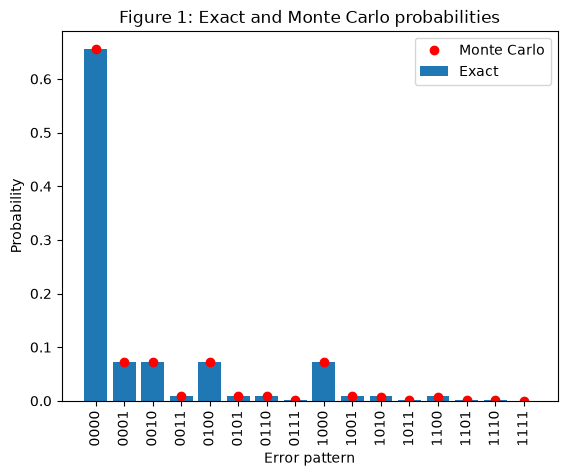

In [81]:
#plot the figure bar chart with x values and label the bar chart Exact
plt.figure()
x = np.arange(16)
plt.bar(x, exact_probabilities, label="Exact")

#Monte Carlo estimates with different patterns and their values 
mc_probability_pattern = np.zeros(16)
"""determines which of the 1 million packets have an exact pattern so that it can use it as an 
estimate for that pattern"""
for i, pattern in enumerate(patterns):
    mc_probability_pattern[i] = np.mean(np.all(errors == np.array([c == "1" for c in pattern]), axis=1))

#plot Monte Carlo estimates
plt.plot(x, mc_probability_pattern, "o", label="Monte Carlo", color="red")

#label the axis and chart
plt.xlabel("Error pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo probabilities")
plt.xticks(x, patterns, rotation=90)
plt.legend()
plt.show()

The figure 1 is comparison between exact and Monte Carlo Probabilities to show how different the value is when numerous trials are taken. Thus, it shows the exact probability of getting each case with different number of errors and the probability of getting each case when 1000 trials are conducted with Monte Carlo estimate.

In [82]:
import pandas as pd

#Seven exact probabilities
exact = np.array([P_A, P_B, P_C, P_AB, P_AC, P_BC, P_ABC])

#Seven empirical probabilities from Monte Carlo
empirical = np.array([A_estimate, B_estimate, C_estimate, AB_estimate, AC_estimate, BC_estimate, ABC_estimate])

#Difference between empirical and exact
difference = empirical - exact

#Label the values on table
table = pd.DataFrame({"Probability": ["P(A)", "P(B)", "P(C)", "P(A ∩ B)", "P(A ∩ C)", "P(B ∩ C)", "P(A ∩ B ∩ C)"],
                      "Exact": exact,
                      "Empirical": empirical,
                      "Difference": difference})

#Display the table
print(table.to_string(index=False))

 Probability  Exact  Empirical  Difference
        P(A) 0.1900   0.190439    0.000439
        P(B) 0.0486   0.048877    0.000277
        P(C) 0.1000   0.100306    0.000306
    P(A ∩ B) 0.0405   0.040735    0.000235
    P(A ∩ C) 0.0190   0.018983   -0.000017
    P(B ∩ C) 0.0243   0.024265   -0.000035
P(A ∩ B ∩ C) 0.0162   0.016123   -0.000077


STEP 5


In [83]:
#Test tv_distance on two identical pmfs
print("TV distance on two identical pmfs: ",tv_distance(np.array([0.2, 0.8]), np.array([0.2, 0.8])))

#Test tv_distance on two pmfs with disjoint support
print("TV distance on two pmfs with disjoint support: ",tv_distance(np.array([1.0, 0.0]), np.array([0.0, 1.0])))

TV distance on two identical pmfs:  0.0
TV distance on two pmfs with disjoint support:  1.0


In [104]:
import numpy as np
import pandas as pd
from scipy.stats import binom, poisson
#Computing exact Binomial pmf and Poisson pmf with same mean and their distance under 5 cases to print a table 
n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]
results = []
for p in p_values:
#Equation for truncating the PMF
    #Poisson pmf mean
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
#Computing exact Binomial pmf and Poisson pmf with same mean
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
#compute distance for the five cases
    distance = tv_distance(binom_pmf, poisson_pmf)
    """compute remaining poisson probability tail beyond K to print next to each ditance and show 
    that the truncation didn't matter"""
    poisson_tail = poisson.sf(K, lam)
#place the 5 cases in a list called results
    results.append((p, lam, K, distance, poisson_tail))
# Print a table for the data
distance_table = pd.DataFrame(results, columns=["p", "lambda = np", "K", "TV Distance", "Poisson Tail > K"])
print(distance_table.to_string(index=False))

     p  lambda = np   K  TV Distance  Poisson Tail > K
0.5000        500.0 968     0.166057      4.572865e-77
0.0500         50.0 212     0.012446      1.895351e-65
0.0050          5.0  70     0.001228      3.605448e-55
0.0010          1.0  41     0.000276      2.680655e-52
0.0005          0.5  35     0.000114      2.405163e-53


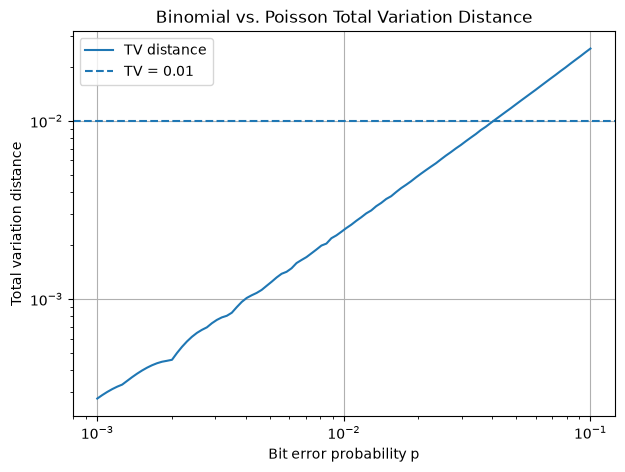

In [93]:
#plot distance on a grid and confirm it increases with p
p_grid = np.logspace(-3, -1, 100)
tv_grid = []
for p in p_grid:
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    distance = tv_distance(binom_pmf, poisson_pmf)
    tv_grid.append(distance)
#create the grid
plt.figure(figsize=(7, 5))
plt.loglog(p_grid, tv_grid, label="TV distance")
plt.axhline(0.01, linestyle="--", label="TV = 0.01")
plt.xlabel("Bit error probability p")
plt.ylabel("Total variation distance")
plt.title("Binomial vs. Poisson Total Variation Distance")
plt.legend()
plt.grid(True)
plt.show()

In [102]:
#Finding the value of p for which for which the distance stays below .01 using bisection 
def tv_for_p(p, n=1000):
    lam = n * p
    K = int(np.ceil(lam + 20*np.sqrt(lam) + 20))
    k = np.arange(K + 1)
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    return tv_distance(binom_pmf, poisson_pmf)
#setting the bracket of p from .001 to .1 to find the value of p for which the distance stays below .01
p_low = 0.001
p_high = 0.1
for _ in range(50):
    p_mid = (p_low + p_high) / 2
    d_mid = tv_for_p(p_mid)
    if d_mid < 0.01:
        p_low = p_mid
    else:
        p_high = p_mid
p_threshold = p_low
tv_threshold = tv_for_p(p_threshold)
#Print the value of the largest p with TV distance less than .01 to two sig figs
print("Largest p with TV distance < 0.01:")
print(f"p = {p_threshold:.3f}")
print(f"TV distance = {tv_threshold:.6f}")

Largest p with TV distance < 0.01:
p = 0.040
TV distance = 0.010000


In [98]:
#Obtaining distance using Le Cam bound to compare probabilities
p_lecam = np.sqrt(0.01 / n)
print(f"Le Cam p at bound = 0.01: {p_lecam:.4f}")

Le Cam p at bound = 0.01: 0.0032


Since .0404 is greater that .0032, the probability of the bisection answer is greater than the Le Cam bound because the Le Cam result is an upper bound, which states the distance is less than or equal to np^2, and that means that even though the bound is .01, the distance has a possibility to be smaller than that to make the statement true.

The Poisson approximation is trustworthy when n is large and p is small so that the mean or lambda remains reasonable.

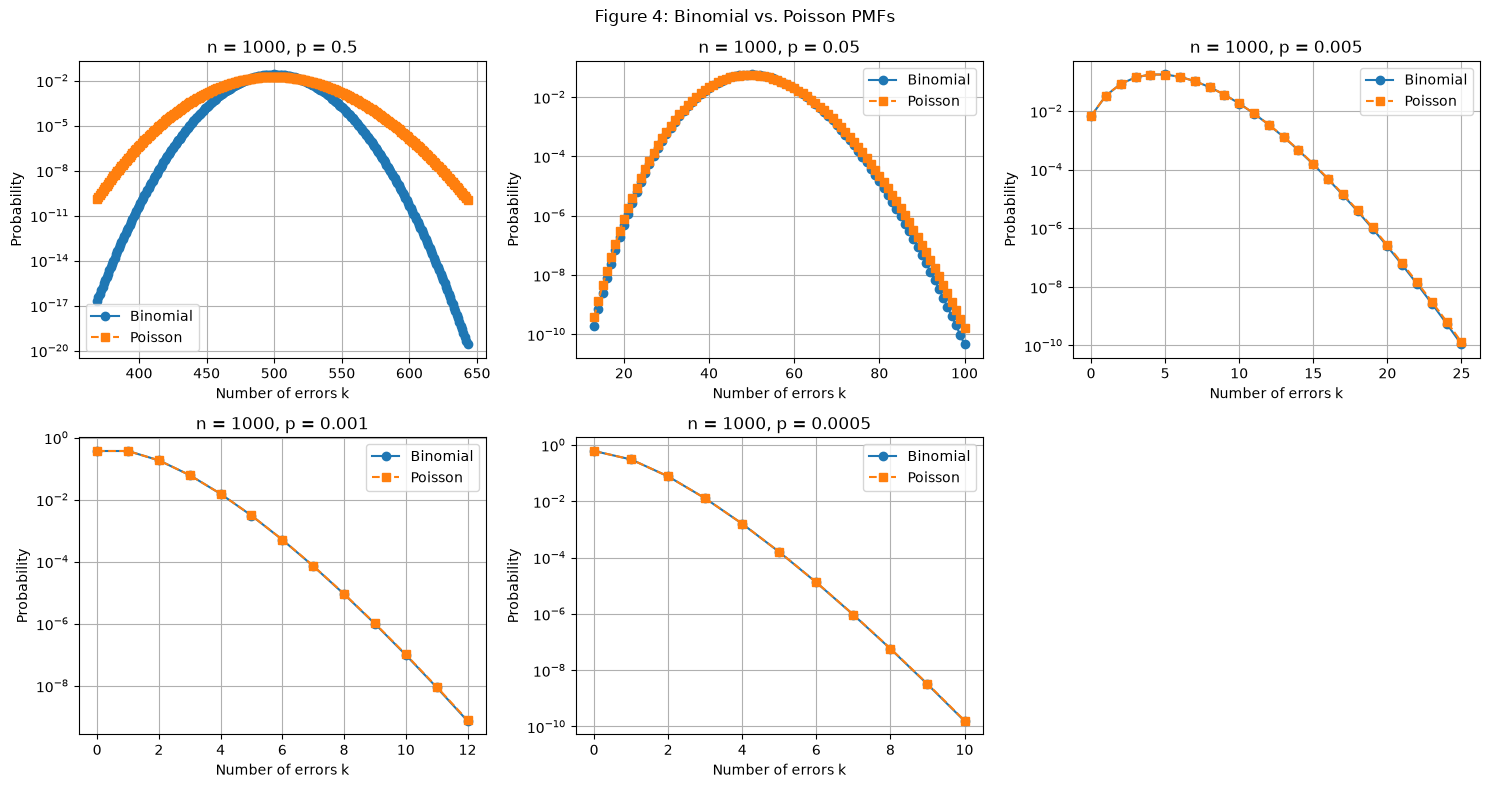

In [100]:
#Figure 4 using 2x3 grid
def get_common_support(n, p):
    lam = n * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    K = min(K, n)
    k = np.arange(K + 1)
    return lam, K, k
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, p in enumerate(p_values):
    #Calculate lambda and support
    lam, K, k = get_common_support(n, p)
    # Calculate the two PMFs
    binom_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    #Find the region where at least one PMF is not negligible
    significant = (binom_pmf > 1e-10) | (poisson_pmf > 1e-10)
    #Get x values in that region
    k_plot = k[significant]
    #Obtain corresponding probabilities
    binom_plot = binom_pmf[significant]
    poisson_plot = poisson_pmf[significant]
    #Plot Binomial
    axes[i].plot(k_plot, binom_plot, 'o-', label='Binomial')
    # Plot Poisson
    axes[i].plot(k_plot, poisson_plot, 's--', label='Poisson')
    #Set up grid
    axes[i].set_yscale('log')
    axes[i].set_xlabel('Number of errors k')
    axes[i].set_ylabel('Probability')
    axes[i].set_title(f'n = 1000, p = {p}')
    axes[i].legend()
    axes[i].grid(True)
#Turn off the unused sixth grid
axes[5].axis('off')
plt.suptitle('Figure 4: Binomial vs. Poisson PMFs')
plt.tight_layout()
plt.show()

This is figure 4 and it compares the different pmfs with different probabilities to show when Poisson approximation should be used. As we can see that for larger p values, the graphs are noticeably different, which means that Poisson aprroximation shouldn't be done. As p decreases and and the n trials remain at 1000, we notice that Poisson approximation gets closer to Binomial. Thus, when p is small, and n remains large, we can use Poisson approximation. 

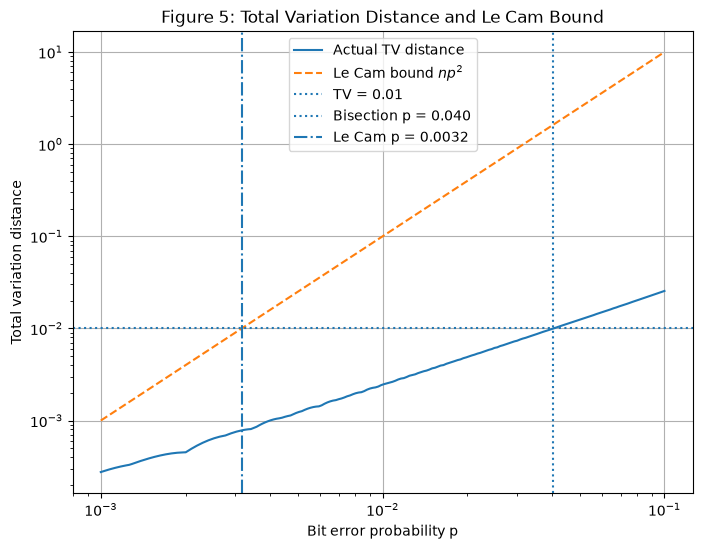

In [103]:
#Figure 5 total variation distance against p
p_grid = np.logspace(-3, -1, 200)
#Calculate actual TV distance
tv_values = np.array([tv_for_p(p, n) for p in p_grid])
#Calculate Le Cam bound
lecam_values = n * p_grid**2
#Calculate the two important p values
p_threshold = 0.0403935857
p_lecam = np.sqrt(0.01 / n)
#Create Figure 5
plt.figure(figsize=(8, 6))
plt.loglog(p_grid, tv_values, label='Actual TV distance')
plt.loglog(p_grid, lecam_values, '--', label=r'Le Cam bound $np^2$')
#TV as 0.01 reference line
plt.axhline(0.01, linestyle=':', label='TV = 0.01')
#Mark bisection result
plt.axvline(p_threshold, linestyle=':', label=f'Bisection p = {p_threshold:.3f}')
# Mark Le Cam point
plt.axvline(p_lecam, linestyle='-.', label=f'Le Cam p = {p_lecam:.4f}')
#Labels
plt.xlabel('Bit error probability p')
plt.ylabel('Total variation distance')
plt.title('Figure 5: Total Variation Distance and Le Cam Bound')
plt.legend()
plt.grid(True)
plt.show()

In the Figure 5, we notice that total variation distance increases when probability p increases, which means that when p is small Poisson approximation is accurate. Thus, the true tv distance at p=.01 is .040 and the only reason that Le Cam has a lower value is because it measures the upper bound at .01 and any other actual distance.